# Temporal post-processing: neighbour-frame views and track rescoring (pipeline, tuned)

## Overview

Parent run: `pipeline-ensemble-extended` (P5b in `SCOPE.md`): the class-wise weighted boxes fusion (WBF, Solovyev et al., arXiv:1910.13302) of the saved predictions of the P5 members and the free members of `SCOPE.md` F65. The output of P5b is the only input of this notebook: its `val_predictions.json` for the val frames and its `submission.csv` for the test frames (the source kernel of the Config). This notebook trains nothing and fuses no new detector. It is a CPU job; the Kaggle push still enables the GPU, which the code does not use.

**What changes.** One thing: the detections of a frame are no longer final after P5b. They are post-processed with the detections of the neighbouring frames of the same clip. There are four mechanisms, each one an ablation row on full val, and a combined row:

| Row | Mechanism | Tuned on quick-val frames |
|---|---|---|
| `baseline` | the P5b detections, unchanged | none |
| `views` | the detections of frames t−1 and t+1, unchanged, enter a WBF with the detections of frame t as two extra views at a lower weight (Seq-NMS idea, arXiv:1602.08465, with WBF in place of Seq-NMS rescoring) | `NEIGHBOUR_WEIGHT_GRID`, `TEMPORAL_IOU_THRESHOLD_GRID` |
| `views_compensated` | the same, but the boxes of frames t−1 and t+1 are first moved into frame t by a homography from ORB feature matches (RANSAC) | the same two grids |
| `track_smoothing` | ByteTrack-style linking (arXiv:2110.06864) of the high-score detections along the clip, then the score of each linked detection is mixed with the mean score of its track (T-CNN idea, arXiv:1604.02532) | `SMOOTHING_WEIGHT_GRID` |
| `track_recovery` | the same linking with the second ByteTrack stage: low-score detections that match a track are lifted to a fraction of the track's mean score | `RECOVERY_FACTOR_GRID` |
| `combined` | the accepted mechanisms together, with the values tuned in their own rows | none (no joint tuning) |

Config constants of the change: `SOURCE_KERNELS`, `NEIGHBOUR_WEIGHT_GRID`, `TEMPORAL_IOU_THRESHOLD_GRID`, `SMOOTHING_WEIGHT_GRID`, `RECOVERY_FACTOR_GRID`. Fixed side choices (not tuned, listed in the Config): the tracker thresholds `TRACK_HIGH_SCORE`, `TRACK_LOW_SCORE`, `TRACK_MATCH_IOU`, `TRACK_MAX_LOST_FRAMES`, and the motion-estimation settings `MOTION_*`. Forced side changes: the matching of detections to tracks is greedy by IoU (SORT, arXiv:1602.00763, uses the Hungarian algorithm; scipy is not in the `kaggle` dependency group, so it cannot be type-checked here), and the tracking rows always use the motion-compensated track positions (the compensation is ablated only in the two `views` rows).

**Why** (`SCOPE.md` F11, F59, F62; `EDA.md` §5 and §8):
- Test frames are consecutive: 48 clips with 35–148 frames each, and the frame gap is always 1 (`EDA.md` §5). The val split holds all frames of its 7 clips (2,846 frames, `EDA.md` §1), and the notebook raises if a clip has a gap in its frame numbers, so the tuning and the evaluation use true neighbours.
- The boxes of the same object move little between adjacent frames: the median IoU of the same `track_id` is 0.895 at k = 1 and 0.806 at k = 2, and 4.7 % of the pairs are below IoU 0.5 at k = 1 (14.8 % at k = 2). It is 0.591 at k = 5 and 0 at k = 30 (`EDA.md` §8, F11). `EDA.md` §8 suspects camera motion as the main cause of the lost overlap (a hypothesis, not measured), which is why a compensated variant is ablated next to the plain one.
- The idea of the views and of the track rescoring (Seq-NMS, T-CNN) is that a detection that is missed or scored low in one frame can be supported by the next frames. How often this happens in the P5b output is not measured yet.
- The 500-detection cap was reached on every val frame in P5 (F59). Extra views add boxes to a list that is already full, so the output is cut at 500 by score after every fusion.
- `AP_small` is reported next to `mAP` for every row, because the brief asks for the effect on small objects (31–38 % of the person and motor boxes are small, `EDA.md` §3).

**Expectation.** A gain of +0.005 to +0.02 mAP@500 is a guess from `SCOPE.md`, not a measurement. The decision rule of `SCOPE.md` §3.10 applies against the baseline row: full-val mAP@500 at least 0.01 higher and a per-clip AP delta of the same sign on at least 5 of the 7 val clips (`val_noise.csv`, column `positive_clips`).

**Tuning and validity.**
- The settings of every row are tuned on the 571 quick-val frames only (every 5th `val/` frame). The tracker and the views read the neighbouring frames of the full clip, which are available in val; only the score of a setting is computed on the quick-val frames.
- A mechanism enters the `combined` row only if its best quick-val mAP@500 is strictly above the quick-val mAP@500 of the baseline. The two `views` rows compete, and the better one is used.
- Metrics are reported on all 2,846 val frames and, in `mAP_outside_quick_val`, on the 2,275 val frames outside the quick-val set, which were not used for tuning (`SCOPE.md` F62). Quick val was also used to select the checkpoints of the members behind P5b, so the full-val score is slightly optimistic.
- Nothing is fitted on training data, and no weights are learned. The tuned values are a few scalars. They are never tuned on the full val or on the test frames.
- Within-clip only: no detection, track or homography crosses a clip boundary. The frame order comes from `frame_id` in the val annotations and from `frame` in `test_images.csv`; the notebook raises if a clip has a gap.
- Test detections are the P5b `submission.csv` (top 500 per image, scores rounded to 4 decimals) processed with the combined setting.

**Comparison with the legacy parent.** P5b fuses current-protocol runs with four legacy runs, so its absolute values carry the legacy protocol (differences from the † notes of `EXPERIMENTS.md`):
- `dmnk1304/faster-cnn-5`: no ignore fill (ignored areas trained as background); GT inside ignore regions not dropped; GT boxes under 1 px dropped; no cudnn determinism settings; pycocotools installed with pip; result file lacks versions, speed protocol and other core keys; legacy output names, `last.pt` saved; no `submission_check.json`.
- `draklowell/retinanet`: the same list, with no `worker_init_fn` instead of the missing cudnn settings.
- `dmnk1304/yolo-3-1280`: no ignore fill; GT inside ignore regions not dropped; checkpoint chosen by Ultralytics fitness on all val frames, no quick-val COCOeval; no `seed_everything`, no `MAX_TRAIN_HOURS` guard; legacy output names, `last.pt` and `runs/` saved; submission coordinates rounded to 1 decimal.
- `dmnk1304/rt-detr-tuned-lr`: the same list as `yolo-3-1280`, with `rtdetr-l.pt` saved as well.

The baseline row of this notebook is the P5b output itself, evaluated by the same code on the same frames, so these differences are on both sides of every delta between a temporal row and the baseline. They are not a confound of the temporal change. They do make the absolute val values of the baseline optimistic (the legacy checkpoints were chosen on full val). The notebook compares nothing with a single legacy run. The members actually fused in P5b are listed in the P5b report and `result.json`; a legacy member whose files were missing was skipped there.

**Extra outputs of this run.** Besides the standard outputs, `per_clip_ap.csv` and `size_breakdown.csv`:
- `history.csv`: the tuning trace (one row per evaluated setting, with quick-val mAP and AP50); there are no training epochs;
- `temporal_ablation.csv`: the baseline, the four mechanisms and the combined row on full val, with the setting, the quick-val mAP, `mAP_outside_quick_val`, the headline metrics, the AP of bus and the AP per clip;
- `val_noise.csv`: per row the AP per clip, the unweighted mean over the 7 clips, the same mean without the 4K clip, and the difference to the baseline with a leave-one-clip-out range and a clip-level bootstrap interval;
- `camera_motion.csv`: per val and test clip, the number of frame pairs, how many fell back to the identity transform, and the median and 95th percentile of the shift of the image centre between adjacent frames, in original pixels;
- `fig_tuning_quick_val.png` and `fig_temporal_ablation.png` (+ `.csv`).

`best.pt` and the training curves do not apply, because nothing is trained.

**Protocol**

- Train: every 5th frame (`FRAME_STEP`) of each of the 56 `train/` clips, 4,868 frames. The split is by clip; no `val/` clip is used for training.
- Validation: all 2,846 frames of the 7 `val/` clips. Quick validation after every epoch: every 5th `val/` frame (`QUICK_VAL_STEP`), 571 frames.
- Ignore regions: in training frames, every ignore box is filled with the frame's own per-channel mean before augmentation, and GT boxes fully inside an ignore box are dropped. Val and test frames are not filled; evaluation treats ignore regions as `iscrowd=1`.
- Metric: pycocotools `COCOeval` on `val/annotations_coco.json` with `maxDets = [1, 100, 500]`; headline `mAP` is AP@[.50:.95] at 500 detections per frame. Inference in fp32 with score threshold 0.001 and at most 500 detections per frame.
- Checkpoint selection: the epoch with the best quick-val mAP. Quick val is a subset of val, so the final val score is slightly optimistic.
- Budget: `EPOCHS` planned epochs (Ultralytics 30, torchvision 12) and a `MAX_TRAIN_HOURS = 6` wall-clock guard, single Tesla T4.
- Reproducibility: `SEED = 42` and deterministic settings. Runs are reproducible in setup but not guaranteed bit-exact.

**How the protocol applies to a post-processing run.**
- The split, the 56 training clips and the ignore handling belong to the training of the members behind P5b. This notebook only checks the frame counts. It does not fill ignore regions, because it trains nothing. Evaluation uses the same `val/annotations_coco.json` with `iscrowd=1`.
- There are no epochs. The "checkpoint" of a mechanism is the setting with the best quick-val mAP@500, and `MAX_TRAIN_HOURS` bounds the tuning search. The input detections come from fp32 inference with score threshold 0.001 and at most 500 detections per frame; every output is capped at 500 detections per frame as well.
- Speed: everything runs on the CPU. `ms_per_image` in `result.json` is the recorded `ms_per_image` of the P5b run plus the wall-clock time per val frame of the motion estimation and of the temporal processing (see `speed_protocol`).
- The runtime is dominated by COCOeval on dense frames (P5: 53 min for five full-val evaluations including the per-clip ones, `SCOPE.md` F61). The plan has about seven full-val evaluations of this kind, plus 12 quick-val trials; this is an estimate to be checked against the log.

**How the neighbour views work**

For frame t, the P5b detections of frame t, t−1 and t+1 are three views. WBF (`ensemble-boxes`, `conf_type="avg"`, class-wise as in `SCOPE.md` F10) clusters the boxes of the same class with IoU above the threshold and averages the coordinates of a cluster weighted by the box scores. The view of frame t has weight 1.0 and each neighbour view has weight `NEIGHBOUR_WEIGHT`. The fused score of a cluster is the weighted mean of the scores in it, rescaled by `min(views, cluster size) / sum of weights`: a box that exists in the current frame only is divided by `1 + 2 × NEIGHBOUR_WEIGHT`, and a box found in all three frames keeps the weighted mean of its scores. The first and the last frame of a clip have one neighbour. The fused detections of a frame are sorted by score and cut at 500.

**How camera motion is compensated**

A drone moves, so the boxes of frame t−1 sit at the wrong place in frame t even for a static object. For each pair of adjacent frames, ORB keypoints (Rublee et al., ICCV 2011) are detected on a grayscale copy whose long side is `MOTION_IMAGE_SIDE` pixels, matched by Hamming distance with cross-check, and a homography is fitted with RANSAC (Fischler and Bolles, 1981; `cv2.findHomography`). The assumption is that moving objects give a minority of the matches, so that RANSAC follows the background. The four corners of each box are mapped through the homography (inverse for frame t+1), the enclosing axis-aligned box is taken and clipped to the image. If a pair has too few matches or inliers, or the fitted transform changes the area by more than a factor of `MOTION_MAX_AREA_CHANGE`, the identity is used and the pair is counted in `camera_motion.csv`. A dense optical flow (torchvision RAFT) or Kornia would give a pixel-wise motion, but would need weights, are slow on the CPU, and Kornia is not installed; the feature-matching homography is the documented option that needs no new package.

**How the tracker and the rescoring work**

Linking follows ByteTrack (Zhang et al., arXiv:2110.06864) in its offline form. Frames are processed in order. Every active track holds its last box, moved into the current frame by the homography of the pair. In each frame the detections with a score of at least `TRACK_HIGH_SCORE` are matched first to the active tracks of the same class by IoU (at least `TRACK_MATCH_IOU`, greedy by descending IoU). For the recovery rows, the unmatched tracks are then matched in the same way to the detections with a score from `TRACK_LOW_SCORE` up to `TRACK_HIGH_SCORE`. An unmatched high-score detection starts a track. A track that was not matched for more than `TRACK_MAX_LOST_FRAMES` frames is removed. Detections below `TRACK_LOW_SCORE` are never linked.

After linking, the mean score of the high-score detections of each track is computed over the whole track, which uses past and future frames (the inference is offline; temporal structure is allowed by the rules). With the smoothing weight λ, a linked high-score detection gets `(1 − λ) × score + λ × track mean`. With the recovery factor ρ, a linked low-score detection gets `max(score, ρ × track mean)`. Unlinked detections keep their score, and scores are clipped to [0, 1]. Boxes are not changed.

Requires: Kaggle GPU T4, Internet on.

## Setup

The only install is `ensemble-boxes` (MIT licence), pinned in the `kaggle` dependency group of `pyproject.toml`; it implements WBF. OpenCV (`cv2`, Apache-2.0) comes with the Kaggle image and is a dependency of Ultralytics, so the `kaggle` group resolves it locally; it is used for ORB features and the RANSAC homography, and its version is recorded in `result.json`. torch, torchvision, pycocotools, numpy, polars and matplotlib come with the Kaggle image too. Their versions are printed here and recorded in `result.json`.

In [1]:
%pip install -q ensemble-boxes==1.0.10

Note: you may need to restart the kernel to use updated packages.


In [2]:
import contextlib
import io
import json
import platform
import random
import time
from dataclasses import asdict, dataclass
from datetime import UTC, datetime
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import torch
from matplotlib.figure import Figure

import cv2
from ensemble_boxes import weighted_boxes_fusion
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from torchvision.ops import box_iou

Seeding helper and the version banner. Nothing here needs a GPU: a CPU session is enough, and `gpu_name` records which kind of session ran.

In [3]:
def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


started_at = datetime.now(UTC).isoformat(timespec="seconds")
gpu_name = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none (CPU session)"
package_versions = {
    "python": platform.python_version(),
    **{
        name: version(name)
        for name in ["torch", "torchvision", "pycocotools", "numpy", "polars", "matplotlib", "ensemble-boxes"]
    },
    "opencv": cv2.__version__,
}
print(" | ".join(f"{name} {value}" for name, value in package_versions.items()), "| GPU:", gpu_name)

python 3.13.18 | torch 2.11.0+cpu | torchvision 0.26.0+cpu | pycocotools 2.0.11 | numpy 2.1.3 | polars 1.35.2 | matplotlib 3.10.0 | ensemble-boxes 1.0.10 | opencv 4.14.0 | GPU: none (CPU session)


## Config

Deviations from the single-run notebooks, with reasons:
- `SOURCE_KERNELS` and `KERNEL_INPUT_ROOT`: the P5b outputs are read from the kernel source attached to this kernel (`val_predictions.json`, `submission.csv`, `result.json`). The mount path `/kaggle/input/notebooks/<owner>/<kernel>` was verified by P5 (`SCOPE.md` F61). The owner in the slug is the account that ran P5b; a missing file raises `FileNotFoundError`.
- `NEIGHBOUR_WEIGHT_GRID`, `TEMPORAL_IOU_THRESHOLD_GRID`: grids of the two `views` rows. The weight of the current frame is `WBF_REFERENCE_WEIGHT = 1.0`, so a neighbour weight below 1 makes the neighbours supporting views. The IoU thresholds bracket the value 0.7 that P5 selected. `WBF_SKIP_BOX_THRESHOLD = 0.001` equals `CONF_THRESHOLD`, so no input box is dropped. `WBF_CONFIDENCE_TYPE = "avg"` is the library default, fixed and not tuned.
- `SMOOTHING_WEIGHT_GRID`, `RECOVERY_FACTOR_GRID`: the weight of the track mean in the smoothed score, and the fraction of the track mean given to a recovered low-score detection.
- `TRACK_HIGH_SCORE`, `TRACK_LOW_SCORE`, `TRACK_MATCH_IOU`, `TRACK_MAX_LOST_FRAMES`: fixed tracker settings, not tuned. The two score thresholds are in the range used by ByteTrack (a high threshold of about 0.5 to 0.6 and a low threshold of 0.1); the IoU gate is loose because the objects are small (10–30 px) and a shift of a few pixels changes their IoU much. A track survives two missing frames.
- `MOTION_*`: the motion estimation. `MOTION_IMAGE_SIDE` is the long side of the grayscale image used for matching, `MOTION_FEATURES` the ORB feature budget, `MOTION_MIN_MATCHES` and `MOTION_MIN_INLIERS` the least evidence for a homography, `MOTION_RANSAC_THRESHOLD` the reprojection threshold in matching-image pixels and `MOTION_MAX_AREA_CHANGE` the largest accepted area change of the fitted transform.
- `VIEW_ROW_NAMES`, `REFERENCE_LABEL`, `FOUR_K_CLIP`, `BUS_CLASS`, `BOOTSTRAP_RESAMPLES`, `BOOTSTRAP_INTERVAL` only parametrise the tuning decision and the analysis sections. The bootstrap resamples the 7 val clips with a seeded generator.
- `MEMBER_RESULT_TOLERANCE`: the largest allowed difference between the recorded `mAP` of P5b and the `mAP` recomputed here from its `val_predictions.json`.
- `MAX_TRAIN_HOURS = 6` bounds the tuning search; the search stops before the next row if the limit is passed. There is no process pool: the pool of P5 hung on Kaggle (`SCOPE.md` F61), so every evaluation runs in the main process.

In [4]:
DATA_ROOT = Path("/kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026")
OUTPUT_DIR = Path("/kaggle/working")
SCRATCH_DIR = Path("/kaggle/temp")
KERNEL_INPUT_ROOT = Path("/kaggle/input/notebooks")
SOURCE_KERNELS = ("dmnk1304/pipeline-ensemble-extended",)

RUN_NAME = "pipeline-temporal"
MODEL_NAME = (
    "temporal post-processing of the P5b fusion output: neighbour-frame WBF views, ORB-homography motion "
    "compensation, ByteTrack-style score smoothing and low-score recovery"
)
FAMILY = "pipeline"
VARIANT = "tuned"
PARENT_RUN = "pipeline-ensemble-extended"
CHANGED_PARAMS: list[str] = [
    "SOURCE_KERNELS",
    "NEIGHBOUR_WEIGHT_GRID",
    "TEMPORAL_IOU_THRESHOLD_GRID",
    "SMOOTHING_WEIGHT_GRID",
    "RECOVERY_FACTOR_GRID",
]

SEED = 42
CLASSES = ["person", "bicycle", "car", "van", "truck", "tricycle", "bus", "motor"]
FRAME_STEP = 5
QUICK_VAL_STEP = 5
EXPECTED_TRAIN_CLIPS = 56
EXPECTED_TRAIN_FRAMES = 4868
EXPECTED_VAL_CLIPS = 7
EXPECTED_VAL_FRAMES = 2846
EXPECTED_QUICK_VAL_FRAMES = 571
EXPECTED_OUTSIDE_QUICK_VAL_FRAMES = 2275
EXPECTED_TEST_FRAMES = 3811
CONF_THRESHOLD = 0.001
MAX_DETECTIONS = 500
MAX_TRAIN_HOURS = 6
IGNORE_STRATEGY = "per_image_mean_fill"

WBF_CONFIDENCE_TYPE = "avg"
WBF_SKIP_BOX_THRESHOLD = 0.001
WBF_REFERENCE_WEIGHT = 1.0
NEIGHBOUR_WEIGHT_GRID = (0.25, 0.5)
TEMPORAL_IOU_THRESHOLD_GRID = (0.6, 0.7)
SMOOTHING_WEIGHT_GRID = (0.25, 0.5)
RECOVERY_FACTOR_GRID = (0.5, 0.8)
VIEW_ROW_NAMES = ("views", "views_compensated")
TRACK_HIGH_SCORE = 0.5
TRACK_LOW_SCORE = 0.1
TRACK_MATCH_IOU = 0.5
TRACK_MAX_LOST_FRAMES = 2
MOTION_IMAGE_SIDE = 960
MOTION_FEATURES = 1500
MOTION_MIN_MATCHES = 12
MOTION_MIN_INLIERS = 10
MOTION_RANSAC_THRESHOLD = 3.0
MOTION_MAX_AREA_CHANGE = 2.0
MEMBER_RESULT_TOLERANCE = 5e-4
SPEED_PROTOCOL = (
    "recorded ms_per_image of the P5b run (its members' inference and fusion, each with its own speed protocol) "
    "plus wall-clock per val frame of the ORB/RANSAC motion estimation and of the temporal processing, CPU, "
    "one process, all val frames"
)

REFERENCE_LABEL = "baseline"
FOUR_K_CLIP = "uav0000268_05773_v"
BUS_CLASS = "bus"
BOOTSTRAP_RESAMPLES = 1000
BOOTSTRAP_INTERVAL = (2.5, 97.5)

SMALL_AREA = 32**2
MEDIUM_AREA = 96**2

FIGURE_SIZE = (12, 5)
FIGURE_DPI = 100
FIGURE_IMAGE_MAX_SIDE = 960

if not (DATA_ROOT / "test_images.csv").is_file():
    raise FileNotFoundError(f"Competition data not found under {DATA_ROOT}")
SCRATCH_DIR.mkdir(parents=True, exist_ok=True)
seed_everything(SEED)

## Data

Frames are listed per split and identified by the key `<clip>/<frame>.jpg`. The members trained on every `FRAME_STEP`-th frame of each `train/` clip; this notebook lists the same split only to check the counts of the protocol. Validation uses every `val/` frame, and quick validation (the tuning set) every `QUICK_VAL_STEP`-th one.

In [5]:
def to_frame_key(path: str | Path) -> str:
    return "/".join(Path(path).parts[-2:])


def list_frames(split: str) -> pl.DataFrame:
    image_paths = sorted(str(path) for path in (DATA_ROOT / split / "images").rglob("*.jpg"))
    return pl.DataFrame({"path": image_paths}, schema={"path": pl.String}).with_columns(
        clip=pl.col("path").str.split("/").list.get(-2),
        frame_key=pl.col("path").str.split("/").list.slice(-2).list.join("/"),
    )


def select_every_nth_frame(frames: pl.DataFrame, step: int) -> pl.DataFrame:
    return frames.filter(pl.int_range(pl.len()).over("clip") % step == 0)


def require_count(name: str, actual: int, expected: int) -> None:
    if actual != expected:
        raise ValueError(f"{name}: expected {expected}, got {actual}")


train_frames = select_every_nth_frame(list_frames("train"), FRAME_STEP)
val_frames = list_frames("val")
quick_val_frames = select_every_nth_frame(val_frames, QUICK_VAL_STEP)

require_count("train clips", train_frames["clip"].n_unique(), EXPECTED_TRAIN_CLIPS)
require_count("train frames", train_frames.height, EXPECTED_TRAIN_FRAMES)
require_count("val clips", val_frames["clip"].n_unique(), EXPECTED_VAL_CLIPS)
require_count("val frames", val_frames.height, EXPECTED_VAL_FRAMES)
require_count("quick-val frames", quick_val_frames.height, EXPECTED_QUICK_VAL_FRAMES)
print(f"train {train_frames.height} | val {val_frames.height} | quick val {quick_val_frames.height} frames")

train 4868 | val 2846 | quick val 571 frames


Ground truth of the val split comes from `annotations_coco.json`; `iscrowd=1` entries and boxes under 1 px are excluded from the GT arrays used by the analyses. The COCOeval itself reads the same file, so ignore regions are handled as `iscrowd=1`. The training-side helpers (ignore boxes of training frames, mean fill) are not needed here: the members applied them when they trained, and this notebook trains nothing.

In [6]:
def load_ground_truth(split: str) -> tuple[pl.DataFrame, dict[str, np.ndarray]]:
    coco = json.loads((DATA_ROOT / split / "annotations_coco.json").read_text())
    images = pl.DataFrame(coco["images"]).select(
        "width",
        "height",
        "frame_id",
        image_id=pl.col("id"),
        frame_key=pl.col("file_name").str.split("/").list.slice(-2).list.join("/"),
    )
    targets = (
        pl.DataFrame(coco["annotations"])
        .filter(pl.col("iscrowd") == 0)
        .select(
            "image_id",
            x1=pl.col("bbox").list.get(0),
            y1=pl.col("bbox").list.get(1),
            x2=pl.col("bbox").list.get(0) + pl.col("bbox").list.get(2),
            y2=pl.col("bbox").list.get(1) + pl.col("bbox").list.get(3),
            class_id=pl.col("category_id") - 1,
        )
        .filter((pl.col("x2") - pl.col("x1") >= 1) & (pl.col("y2") - pl.col("y1") >= 1))
        .join(images.select("image_id", "frame_key"), on="image_id")
    )
    target_columns = ["x1", "y1", "x2", "y2", "class_id"]
    targets_by_key = {key: np.zeros((0, 5), dtype=np.float32) for key in images["frame_key"]}
    for (key,), frame_targets in targets.group_by("frame_key"):
        targets_by_key[str(key)] = frame_targets.select(target_columns).to_numpy().astype(np.float32)
    return images, targets_by_key

Apply the helper to the val split and index the frames: image ids, image sizes, paths and the key lists. The quick-val frames are the tuning set, and the 2,275 val frames outside them give the number that was not used for tuning. The test frames come from `test_images.csv`; the competition data has no `sample_submission.csv`.

In [7]:
val_images, val_targets_by_key = load_ground_truth("val")
val_image_id_by_key = dict(val_images.select("frame_key", "image_id").iter_rows())
key_by_val_image_id = {image_id: key for key, image_id in val_image_id_by_key.items()}
val_size_by_key = {
    key: (width, height) for key, width, height in val_images.select("frame_key", "width", "height").iter_rows()
}
val_path_by_key = dict(val_frames.select("frame_key", "path").iter_rows())
val_keys = val_frames["frame_key"].to_list()
quick_val_keys = quick_val_frames["frame_key"].to_list()
quick_val_image_ids = [val_image_id_by_key[key] for key in quick_val_keys]
quick_val_key_set = set(quick_val_keys)
outside_quick_val_image_ids = [
    image_id for key, image_id in val_image_id_by_key.items() if key not in quick_val_key_set
]
require_count("frames outside quick val", len(outside_quick_val_image_ids), EXPECTED_OUTSIDE_QUICK_VAL_FRAMES)
val_clips = sorted(val_frames["clip"].unique().to_list())
if FOUR_K_CLIP not in val_clips:
    raise ValueError(f"The 4K clip {FOUR_K_CLIP} is not a val clip")

test_images = pl.read_csv(DATA_ROOT / "test_images.csv").with_columns(
    frame_key=pl.col("file_name").str.split("/").list.slice(-2).list.join("/")
)
require_count("test frames", test_images.height, EXPECTED_TEST_FRAMES)
test_keys = test_images["frame_key"].to_list()
test_key_by_image_id = dict(test_images.select("image_id", "frame_key").iter_rows())
test_path_by_key = {
    key: str(DATA_ROOT / file_name) for key, file_name in test_images.select("frame_key", "file_name").iter_rows()
}
test_size_by_key = {
    key: (width, height) for key, width, height in test_images.select("frame_key", "width", "height").iter_rows()
}
print(f"val GT frames {len(val_targets_by_key)} | test frames {len(test_keys)} | val clips {len(val_clips)}")

val GT frames 2846 | test frames 3811 | val clips 7


Frame order inside each clip. Val uses `frame_id` of the annotations and test uses `frame` of `test_images.csv`. The temporal mechanisms assume that adjacent list entries are adjacent frames, so the function raises if a clip has a gap or a repeated number.

In [8]:
def group_keys_by_clip(frames: pl.DataFrame) -> dict[str, list[str]]:
    ordered = frames.sort("clip", "frame_number")
    broken_pairs = ordered.select((pl.col("frame_number").diff().over("clip") != 1).sum()).item()
    if broken_pairs:
        raise ValueError(f"{broken_pairs} adjacent frame pairs are not consecutive")
    return {str(clip): group["frame_key"].to_list() for (clip,), group in ordered.group_by("clip", maintain_order=True)}


val_clip_keys = group_keys_by_clip(
    val_frames.join(val_images.select("frame_key", "frame_id"), on="frame_key").with_columns(
        frame_number=pl.col("frame_id")
    )
)
test_clip_keys = group_keys_by_clip(test_images.with_columns(frame_number=pl.col("frame")))
require_count("val clips with order", len(val_clip_keys), EXPECTED_VAL_CLIPS)
print(f"val clips {len(val_clip_keys)} | test clips {len(test_clip_keys)} | all adjacent frame numbers differ by 1")

val clips 7 | test clips 48 | all adjacent frame numbers differ by 1


Evaluation helpers, copied from the single-run notebooks: conversion to the COCO results format and COCOeval at `maxDets = [1, 100, 500]`. `COCO.loadRes` mutates its input, so `evaluate_coco` passes copies. `COCOeval.eval` mixes value types, so the precision array is checked explicitly before slicing. `FrameDetections` is `(boxes, scores, class_ids)` with boxes `xyxy` in original pixels, float scores and 0-based class ids.

In [9]:
type FrameDetections = tuple[np.ndarray, np.ndarray, np.ndarray]


def to_coco_results(
    detections_by_key: dict[str, FrameDetections], image_id_by_key: dict[str, int]
) -> list[dict[str, object]]:
    return [
        {
            "image_id": image_id_by_key[key],
            "category_id": int(class_id) + 1,
            "bbox": [round(x1, 2), round(y1, 2), round(x2 - x1, 2), round(y2 - y1, 2)],
            "score": round(score, 4),
        }
        for key, (boxes, scores, class_ids) in detections_by_key.items()
        for (x1, y1, x2, y2), score, class_id in zip(boxes.tolist(), scores.tolist(), class_ids.tolist(), strict=True)
    ]


def load_coco_ground_truth(split: str) -> COCO:
    with contextlib.redirect_stdout(io.StringIO()):
        return COCO(str(DATA_ROOT / split / "annotations_coco.json"))


def evaluate_coco(
    ground_truth: COCO, detections: list[dict[str, object]], image_ids: list[int] | None = None
) -> COCOeval:
    with contextlib.redirect_stdout(io.StringIO()):
        evaluator = COCOeval(ground_truth, ground_truth.loadRes([dict(item) for item in detections]), "bbox")
        evaluator.params.maxDets = [1, 100, MAX_DETECTIONS]
        if image_ids is not None:
            evaluator.params.imgIds = image_ids
        evaluator.evaluate()
        evaluator.accumulate()
        evaluator.summarize()
    return evaluator


def read_precision_at_max_detections(evaluator: COCOeval) -> np.ndarray:
    precision = evaluator.eval["precision"]
    if not isinstance(precision, np.ndarray):
        raise RuntimeError("COCOeval has no precision array; call accumulate() first")
    return precision[:, :, :, 0, -1]


def compute_map_at_max_detections(evaluator: COCOeval) -> float:
    precision = read_precision_at_max_detections(evaluator)
    return float(np.mean(precision[precision > -1]))


val_ground_truth = load_coco_ground_truth("val")

Headline metrics and the per-class table. `stats[0]` is AP at maxDets 100; `stats[1..5]` and `stats[8]` are already at maxDets 500. Size buckets are COCO's 32² / 96² in original pixels.

In [10]:
def summarise_metrics(evaluator: COCOeval) -> dict[str, float]:
    stats = evaluator.stats
    return {
        "mAP": round(compute_map_at_max_detections(evaluator), 4),
        "mAP_maxdet100": round(float(stats[0]), 4),
        "AP50": round(float(stats[1]), 4),
        "AP75": round(float(stats[2]), 4),
        "AP_small": round(float(stats[3]), 4),
        "AP_medium": round(float(stats[4]), 4),
        "AP_large": round(float(stats[5]), 4),
        "AR500": round(float(stats[8]), 4),
    }


def average_valid_precision(precision: np.ndarray) -> float | None:
    valid_precision = precision[precision > -1]
    return round(float(valid_precision.mean()), 4) if valid_precision.size else None


def build_per_class_ap(evaluator: COCOeval) -> pl.DataFrame:
    precision = read_precision_at_max_detections(evaluator)
    return pl.DataFrame(
        [
            {
                "class_id": class_id,
                "class_name": class_name,
                "AP": average_valid_precision(precision[:, :, class_id]),
                "AP50": average_valid_precision(precision[0, :, class_id]),
            }
            for class_id, class_name in enumerate(CLASSES)
        ],
        schema={"class_id": pl.Int64, "class_name": pl.String, "AP": pl.Float64, "AP50": pl.Float64},
    )

Per-clip AP. The val set has 7 clips, and one 4K clip is 34 % of its frames (EDA summary `EDA.md`, §5), so COCOeval also runs on each clip alone: the detections are filtered to the clip's frames and evaluated against the same ground truth. `build_metric_row` turns one evaluation into the flat row used by the ablation: the headline metrics, the AP of the bus class and the AP of every clip (`AP_<clip>`). `evaluate_detections` runs the whole chain for one set of detections.

In [11]:
def round_valid_metric(value: float) -> float | None:
    return round(float(value), 4) if value > -1 else None


def build_per_clip_ap(predictions: list[dict[str, object]]) -> pl.DataFrame:
    image_ids_by_clip = (
        val_images.with_columns(clip=pl.col("frame_key").str.split("/").list.get(0))
        .group_by("clip")
        .agg(pl.col("image_id"))
        .sort("clip")
    )
    rows = []
    for clip, image_ids in image_ids_by_clip.iter_rows():
        clip_image_ids = set(image_ids)
        clip_predictions = [item for item in predictions if item["image_id"] in clip_image_ids]
        evaluator = evaluate_coco(val_ground_truth, clip_predictions, image_ids)
        rows.append(
            {
                "clip": clip,
                "frames": len(image_ids),
                "AP": round(compute_map_at_max_detections(evaluator), 4),
                "AP50": round_valid_metric(evaluator.stats[1]),
                "AP_small": round_valid_metric(evaluator.stats[3]),
            }
        )
    return pl.DataFrame(
        rows,
        schema={
            "clip": pl.String,
            "frames": pl.Int64,
            "AP": pl.Float64,
            "AP50": pl.Float64,
            "AP_small": pl.Float64,
        },
    )


def build_metric_row(evaluator: COCOeval, per_clip_ap: pl.DataFrame) -> dict[str, float]:
    bus_ap = build_per_class_ap(evaluator).filter(pl.col("class_name") == BUS_CLASS)["AP"].item()
    return {
        **summarise_metrics(evaluator),
        "AP_bus": float(bus_ap),
        **{f"AP_{clip}": float(ap) for clip, ap in per_clip_ap.select("clip", "AP").iter_rows()},
    }


def compute_outside_quick_val_map(predictions: list[dict[str, object]]) -> float:
    outside_ids = set(outside_quick_val_image_ids)
    outside_predictions = [item for item in predictions if item["image_id"] in outside_ids]
    evaluator = evaluate_coco(val_ground_truth, outside_predictions, outside_quick_val_image_ids)
    return round(compute_map_at_max_detections(evaluator), 4)


def evaluate_detections(detections_by_key: dict[str, FrameDetections]) -> dict[str, float]:
    predictions = to_coco_results(detections_by_key, val_image_id_by_key)
    evaluator = evaluate_coco(val_ground_truth, predictions)
    return {
        **build_metric_row(evaluator, build_per_clip_ap(predictions)),
        "mAP_outside_quick_val": compute_outside_quick_val_map(predictions),
    }

Input detections: the P5b output. Its files are read from `KERNEL_INPUT_ROOT / <owner> / <kernel>`; the source kernel must have finished and must be attached as a kernel source. For validation, `val_predictions.json` (COCO results format, at most 500 detections per frame) is turned into `(boxes, scores, class_ids)` per frame key; frames without detections get empty arrays. For test, `submission.csv` (`class score x y w h` groups, top 500 per image) is parsed the same way, and every test frame must be present. Boxes stay in float64, so the P5b output round-trips through the COCO format without change. The `result.json` of P5b provides the recorded `mAP`, `ms_per_image` and `train_hours`, and its `run` must equal the kernel slug.

In [12]:
SOURCE_RESULT_KEYS = ("mAP", "ms_per_image", "train_hours")


def read_source_file(kernel: str, file_name: str) -> Path:
    path = KERNEL_INPUT_ROOT / kernel / file_name
    if not path.is_file():
        raise FileNotFoundError(f"{path} is missing: attach the finished source kernel {kernel}")
    return path


def read_source_result(kernel: str) -> dict[str, float]:
    result = json.loads(read_source_file(kernel, "result.json").read_text())
    if result["run"] != kernel.split("/")[1]:
        raise ValueError(f"{kernel}: result.json belongs to run {result['run']}")
    return {key: float(result[key]) for key in SOURCE_RESULT_KEYS}


def build_empty_detections() -> FrameDetections:
    return np.zeros((0, 4)), np.zeros(0), np.zeros(0, dtype=np.int64)


def load_source_val_detections(kernel: str) -> dict[str, FrameDetections]:
    predictions = (
        pl.DataFrame(
            json.loads(read_source_file(kernel, "val_predictions.json").read_text()),
            schema={"image_id": pl.Int64, "category_id": pl.Int64, "bbox": pl.List(pl.Float64), "score": pl.Float64},
        )
        .select(
            "image_id",
            "score",
            x1=pl.col("bbox").list.get(0),
            y1=pl.col("bbox").list.get(1),
            x2=pl.col("bbox").list.get(0) + pl.col("bbox").list.get(2),
            y2=pl.col("bbox").list.get(1) + pl.col("bbox").list.get(3),
            class_id=pl.col("category_id") - 1,
        )
        .filter((pl.col("x2") > pl.col("x1")) & (pl.col("y2") > pl.col("y1")))
    )
    detections_by_key = {key: build_empty_detections() for key in val_keys}
    for (image_id,), frame in predictions.group_by("image_id"):
        detections_by_key[key_by_val_image_id[int(image_id)]] = (
            frame.select("x1", "y1", "x2", "y2").to_numpy(),
            frame["score"].to_numpy(),
            frame["class_id"].to_numpy(),
        )
    return detections_by_key


def load_source_test_detections(kernel: str) -> dict[str, FrameDetections]:
    submission = pl.read_csv(
        read_source_file(kernel, "submission.csv"), schema={"image_id": pl.String, "PredictionString": pl.String}
    ).with_columns(pl.col("PredictionString").fill_null(""))
    detections_by_key: dict[str, FrameDetections] = {}
    for image_id, prediction_string in submission.iter_rows():
        groups = np.array(prediction_string.split(), dtype=np.float64).reshape(-1, 6)
        boxes = np.stack([groups[:, 2], groups[:, 3], groups[:, 2] + groups[:, 4], groups[:, 3] + groups[:, 5]], axis=1)
        detections_by_key[test_key_by_image_id[image_id]] = (boxes, groups[:, 1], groups[:, 0].astype(np.int64))
    require_count(f"{kernel} test frames", len(detections_by_key), EXPECTED_TEST_FRAMES)
    return detections_by_key

Load the P5b output and show one row. `val_detections` and `test_detections` count the detections that enter the post-processing. The frame keys of the loaded detections must be exactly the keys of the clip lists.

In [13]:
require_count("source kernels", len(SOURCE_KERNELS), 1)
SOURCE_KERNEL = SOURCE_KERNELS[0]
source_result = read_source_result(SOURCE_KERNEL)
val_base = load_source_val_detections(SOURCE_KERNEL)
test_base = load_source_test_detections(SOURCE_KERNEL)
require_count("val frames in clip lists", sum(len(keys) for keys in val_clip_keys.values()), len(val_base))
require_count("test frames in clip lists", sum(len(keys) for keys in test_clip_keys.values()), len(test_base))
pl.DataFrame(
    {
        "kernel": [SOURCE_KERNEL],
        "recorded_mAP": [source_result["mAP"]],
        "val_detections": [sum(len(item[1]) for item in val_base.values())],
        "test_detections": [sum(len(item[1]) for item in test_base.values())],
    }
)

kernel,recorded_mAP,val_detections,test_detections
str,f64,i64,i64
"""dmnk1304/pipeline-ensemble-ext…",0.2904,1423000,1905500


Baseline row and input check. The saved full-val detections of P5b are evaluated here (full-val COCOeval, per-clip COCOeval, bus AP and the mAP outside the quick-val frames). The recomputed `mAP` must match the recorded `mAP` of P5b within `MEMBER_RESULT_TOLERANCE`; otherwise the notebook raises, because the attached files would not belong to the run it expects. This is the `baseline` row of the ablation.

In [14]:
baseline_row = evaluate_detections(val_base)
if abs(baseline_row["mAP"] - source_result["mAP"]) > MEMBER_RESULT_TOLERANCE:
    raise ValueError(f"Recomputed mAP {baseline_row['mAP']} differs from recorded {source_result['mAP']}")
pl.DataFrame(
    {
        "recomputed_mAP": [baseline_row["mAP"]],
        "recorded_mAP": [source_result["mAP"]],
        "mAP_outside_quick_val": [baseline_row["mAP_outside_quick_val"]],
        "AP_small": [baseline_row["AP_small"]],
    }
)

recomputed_mAP,recorded_mAP,mAP_outside_quick_val,AP_small
f64,f64,f64,f64
0.2904,0.2904,0.2901,0.1521


Camera motion. For each pair of adjacent frames in a clip, ORB keypoints are matched and a homography `H` from frame t to frame t+1 is fitted with RANSAC, in original-image pixel coordinates (see the Overview). `estimate_pair_motion` returns `None` when the evidence is too weak or the transform is implausible; the caller then uses the identity and counts the pair. Frames are decoded as grayscale and downscaled to `MOTION_IMAGE_SIDE` on the long side, so a 4K frame costs about as much as a 1344 px one.

In [15]:
type Features = tuple[np.ndarray, np.ndarray | None, float]

feature_detector = cv2.ORB.create(nfeatures=MOTION_FEATURES)
feature_matcher = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=True)


def extract_features(path: str) -> Features:
    image = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if image is None:
        raise FileNotFoundError(f"Cannot read {path}")
    scale = MOTION_IMAGE_SIDE / max(image.shape)
    resized = cv2.resize(image, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
    keypoints, descriptors = feature_detector.detectAndCompute(resized, None)
    points = np.array([keypoint.pt for keypoint in keypoints], dtype=np.float32).reshape(-1, 2)
    return points, descriptors, scale


def estimate_pair_motion(first: Features, second: Features) -> np.ndarray | None:
    first_points, first_descriptors, scale = first
    second_points, second_descriptors, _ = second
    if first_descriptors is None or second_descriptors is None:
        return None
    matches = feature_matcher.match(first_descriptors, second_descriptors)
    if len(matches) < MOTION_MIN_MATCHES:
        return None
    source = first_points[[match.queryIdx for match in matches]]
    target = second_points[[match.trainIdx for match in matches]]
    matrix, inliers = cv2.findHomography(source, target, cv2.RANSAC, MOTION_RANSAC_THRESHOLD)
    if matrix is None or inliers.sum() < MOTION_MIN_INLIERS:
        return None
    area_change = abs(float(np.linalg.det(matrix[:2, :2])))
    if not 1 / MOTION_MAX_AREA_CHANGE < area_change < MOTION_MAX_AREA_CHANGE:
        return None
    to_matching_image = np.diag([scale, scale, 1.0])
    return np.linalg.inv(to_matching_image) @ matrix @ to_matching_image

Run the estimation for every clip of a split. `estimate_clip_motion` returns an array of shape `(frames − 1, 3, 3)` with the transform from each frame to the next, and the number of pairs that fell back to the identity. The wall-clock time of the val run enters `ms_per_image`.

In [16]:
def estimate_clip_motion(paths: list[str]) -> tuple[np.ndarray, int]:
    features = [extract_features(path) for path in paths]
    estimates = [estimate_pair_motion(first, second) for first, second in zip(features[:-1], features[1:], strict=True)]
    fallback_count = sum(estimate is None for estimate in estimates)
    return np.stack([np.eye(3) if estimate is None else estimate for estimate in estimates]), fallback_count


def estimate_split_motion(
    clip_keys: dict[str, list[str]], path_by_key: dict[str, str]
) -> tuple[dict[str, np.ndarray], dict[str, int]]:
    matrices_by_clip = {}
    fallbacks_by_clip = {}
    for clip, keys in clip_keys.items():
        matrices_by_clip[clip], fallbacks_by_clip[clip] = estimate_clip_motion([path_by_key[key] for key in keys])
    return matrices_by_clip, fallbacks_by_clip


motion_started = time.perf_counter()
val_matrices_by_clip, val_fallbacks_by_clip = estimate_split_motion(val_clip_keys, val_path_by_key)
val_motion_seconds = time.perf_counter() - motion_started
test_matrices_by_clip, test_fallbacks_by_clip = estimate_split_motion(test_clip_keys, test_path_by_key)
print(
    f"motion: val {val_motion_seconds / 60:.1f} min | "
    f"identity fallbacks val {sum(val_fallbacks_by_clip.values())} of {len(val_keys) - len(val_clip_keys)} pairs | "
    f"test {sum(test_fallbacks_by_clip.values())} of {len(test_keys) - len(test_clip_keys)} pairs"
)

motion: val 3.5 min | identity fallbacks val 0 of 2839 pairs | test 17 of 3763 pairs


Camera motion per clip, written to `camera_motion.csv`. How to read this table: one row per clip. `pairs` is the number of adjacent frame pairs, `identity_fallbacks` the pairs without a usable homography. `median_centre_shift_px` and `p95_centre_shift_px` are the median and 95th percentile of the distance, in original pixels, between the image centre and its image under the transform to the next frame.

In [17]:
def summarise_camera_motion(
    split: str,
    clip_keys: dict[str, list[str]],
    matrices_by_clip: dict[str, np.ndarray],
    fallbacks_by_clip: dict[str, int],
    size_by_key: dict[str, tuple[int, int]],
) -> list[dict[str, object]]:
    rows: list[dict[str, object]] = []
    for clip, keys in clip_keys.items():
        width, height = size_by_key[keys[0]]
        centre = np.array([width / 2, height / 2, 1.0])
        moved = matrices_by_clip[clip] @ centre
        shifts = np.hypot(*(moved[:, :2] / moved[:, 2:] - centre[:2]).T)
        rows.append(
            {
                "split": split,
                "clip": clip,
                "pairs": len(keys) - 1,
                "identity_fallbacks": fallbacks_by_clip[clip],
                "median_centre_shift_px": round(float(np.median(shifts)), 2),
                "p95_centre_shift_px": round(float(np.percentile(shifts, 95)), 2),
            }
        )
    return rows


camera_motion = pl.DataFrame(
    [
        *summarise_camera_motion("val", val_clip_keys, val_matrices_by_clip, val_fallbacks_by_clip, val_size_by_key),
        *summarise_camera_motion(
            "test", test_clip_keys, test_matrices_by_clip, test_fallbacks_by_clip, test_size_by_key
        ),
    ]
)
camera_motion.write_csv(OUTPUT_DIR / "camera_motion.csv")
camera_motion

split,clip,pairs,identity_fallbacks,median_centre_shift_px,p95_centre_shift_px
str,str,i64,i64,f64,f64
"""val""","""uav0000086_00000_v""",463,0,0.58,1.51
"""val""","""uav0000117_02622_v""",348,0,5.01,19.78
"""val""","""uav0000137_00458_v""",232,0,1.94,41.59
"""val""","""uav0000182_00000_v""",362,0,1.3,18.53
"""val""","""uav0000268_05773_v""",977,0,0.62,2.36
…,…,…,…,…,…
"""test""","""clip_044""",82,1,8.02,32.41
"""test""","""clip_045""",70,0,2.25,9.47
"""test""","""clip_046""",139,1,2.01,7.18


## Model

The model of this run is a deterministic post-processing function with no learned weights. A `TemporalSetting` holds the choice of mechanisms: a neighbour weight above 0 switches the views on, `is_compensated` moves the neighbour boxes with the homography, a smoothing weight above 0 switches the track smoothing on, and a recovery factor above 0 switches the second linking stage and the recovery on. `fuse_frame` is the WBF call of P5: it normalises the boxes by the image size, calls `weighted_boxes_fusion` of `ensemble-boxes`, sorts by score, keeps the top `MAX_DETECTIONS`, scales back to pixels and clips boxes and scores.

In [18]:
def fuse_frame(
    member_detections: list[FrameDetections],
    size: tuple[int, int],
    weights: tuple[float, ...],
    iou_threshold: float,
    skip_box_threshold: float,
) -> FrameDetections:
    if all(len(scores) == 0 for _, scores, _ in member_detections):
        return build_empty_detections()
    width, height = size
    scale = np.array([width, height, width, height], dtype=np.float64)
    boxes, scores, class_ids = weighted_boxes_fusion(
        [(boxes / scale).clip(0, 1) for boxes, _, _ in member_detections],
        [scores for _, scores, _ in member_detections],
        [class_ids for _, _, class_ids in member_detections],
        weights=list(weights),
        iou_thr=iou_threshold,
        skip_box_thr=skip_box_threshold,
        conf_type=WBF_CONFIDENCE_TYPE,
    )
    top_indices = np.argsort(-scores, kind="stable")[:MAX_DETECTIONS]
    return (
        (boxes[top_indices] * scale).clip(0, scale),
        scores[top_indices].clip(0.0, 1.0),
        class_ids[top_indices].astype(np.int64),
    )


@dataclass(frozen=True)
class TemporalSetting:
    neighbour_weight: float = 0.0
    iou_threshold: float = 0.7
    is_compensated: bool = False
    smoothing_weight: float = 0.0
    recovery_factor: float = 0.0

    @property
    def has_views(self) -> bool:
        return self.neighbour_weight > 0

    @property
    def has_tracking(self) -> bool:
        return self.smoothing_weight > 0 or self.recovery_factor > 0

Moving boxes between frames. `warp_boxes` maps the four corners of each box through a homography and takes the enclosing axis-aligned box, clipped to the image. `warp_detections` applies it to a frame and drops boxes that collapse to zero size after clipping, because WBF removes zero-area boxes with a warning.

In [19]:
def warp_boxes(boxes: np.ndarray, matrix: np.ndarray, size: tuple[int, int]) -> np.ndarray:
    if len(boxes) == 0:
        return boxes
    corners = np.stack(
        [boxes[:, [0, 1]], boxes[:, [2, 1]], boxes[:, [2, 3]], boxes[:, [0, 3]]],
        axis=1,
    )
    homogeneous = np.concatenate([corners, np.ones((len(boxes), 4, 1))], axis=2) @ matrix.T
    with np.errstate(divide="ignore", invalid="ignore"):
        projected = homogeneous[..., :2] / homogeneous[..., 2:]
    width, height = size
    limit = np.array([width, height, width, height], dtype=np.float64)
    return np.concatenate([projected.min(axis=1), projected.max(axis=1)], axis=1).clip(0, limit)


def warp_detections(detections: FrameDetections, matrix: np.ndarray, size: tuple[int, int]) -> FrameDetections:
    boxes, scores, class_ids = detections
    warped = warp_boxes(boxes, matrix, size)
    is_valid = (warped[:, 2] > warped[:, 0]) & (warped[:, 3] > warped[:, 1])
    return warped[is_valid], scores[is_valid], class_ids[is_valid]

Neighbour views. For the frame at `index` of a clip, the views are its own detections (weight `WBF_REFERENCE_WEIGHT`) and, when they exist, the detections of the previous and the next frame (weight `neighbour_weight`), moved into the current frame if `matrices` is given. `matrices[i]` is the transform from frame i to frame i+1, so the previous frame uses `matrices[index - 1]` and the next frame uses the inverse of `matrices[index]`.

In [20]:
def fuse_with_neighbours(
    index: int,
    keys: list[str],
    matrices: np.ndarray | None,
    base: dict[str, FrameDetections],
    size_by_key: dict[str, tuple[int, int]],
    setting: TemporalSetting,
) -> FrameDetections:
    size = size_by_key[keys[index]]
    views = [base[keys[index]]]
    weights = [WBF_REFERENCE_WEIGHT]
    if index > 0:
        previous = base[keys[index - 1]]
        views.append(previous if matrices is None else warp_detections(previous, matrices[index - 1], size))
        weights.append(setting.neighbour_weight)
    if index < len(keys) - 1:
        following = base[keys[index + 1]]
        views.append(
            following if matrices is None else warp_detections(following, np.linalg.inv(matrices[index]), size)
        )
        weights.append(setting.neighbour_weight)
    return fuse_frame(views, size, tuple(weights), setting.iou_threshold, WBF_SKIP_BOX_THRESHOLD)

Matching for the tracker. `compute_class_aware_iou` gives the IoU of every track box with every detection and sets it to 0 for pairs of different classes (class-aware association, `SCOPE.md` F10). `match_greedily` accepts pairs in descending IoU order while neither side is used and the IoU reaches the gate.

In [21]:
def compute_class_aware_iou(
    track_boxes: np.ndarray, track_classes: np.ndarray, boxes: np.ndarray, class_ids: np.ndarray
) -> np.ndarray:
    if len(track_boxes) == 0 or len(boxes) == 0:
        return np.zeros((len(track_boxes), len(boxes)))
    iou = box_iou(
        torch.from_numpy(np.ascontiguousarray(track_boxes, dtype=np.float32)),
        torch.from_numpy(np.ascontiguousarray(boxes, dtype=np.float32)),
    ).numpy()
    return iou * (track_classes[:, None] == class_ids[None, :])


def match_greedily(iou: np.ndarray, threshold: float) -> list[tuple[int, int]]:
    rows, columns = np.nonzero(iou >= threshold)
    order = np.argsort(-iou[rows, columns], kind="stable")
    used_rows: set[int] = set()
    used_columns: set[int] = set()
    pairs = []
    for row, column in zip(rows[order].tolist(), columns[order].tolist(), strict=True):
        if row not in used_rows and column not in used_columns:
            used_rows.add(row)
            used_columns.add(column)
            pairs.append((row, column))
    return pairs

Linking one clip. The function returns, for every frame, an integer array with the track id of each detection (-1 for detections that are not linked). Active tracks are moved into the current frame by the homography of the pair, matched in the stages described in the Overview, aged, and removed after `TRACK_MAX_LOST_FRAMES` missing frames. `has_low_stage` switches the second stage on.

In [22]:
def link_clip(
    clip_detections: list[FrameDetections], matrices: np.ndarray, size: tuple[int, int], has_low_stage: bool
) -> list[np.ndarray]:
    track_boxes = np.zeros((0, 4))
    track_classes = np.zeros(0, dtype=np.int64)
    track_ids = np.zeros(0, dtype=np.int64)
    track_lost = np.zeros(0, dtype=np.int64)
    next_id = 0
    assignments = []
    for index, (boxes, scores, class_ids) in enumerate(clip_detections):
        if index > 0:
            track_boxes = warp_boxes(track_boxes, matrices[index - 1], size)
        assigned = np.full(len(scores), -1, dtype=np.int64)
        is_high = scores >= TRACK_HIGH_SCORE
        stages = [np.flatnonzero(is_high)]
        if has_low_stage:
            stages.append(np.flatnonzero((scores >= TRACK_LOW_SCORE) & ~is_high))
        is_matched = np.zeros(len(track_boxes), dtype=bool)
        for candidates in stages:
            free_tracks = np.flatnonzero(~is_matched)
            iou = compute_class_aware_iou(
                track_boxes[free_tracks], track_classes[free_tracks], boxes[candidates], class_ids[candidates]
            )
            for row, column in match_greedily(iou, TRACK_MATCH_IOU):
                assigned[candidates[column]] = track_ids[free_tracks[row]]
                track_boxes[free_tracks[row]] = boxes[candidates[column]]
                is_matched[free_tracks[row]] = True
        track_lost = np.where(is_matched, 0, track_lost + 1)
        new_detections = np.flatnonzero(is_high & (assigned < 0))
        assigned[new_detections] = np.arange(next_id, next_id + len(new_detections))
        next_id += len(new_detections)
        track_boxes = np.concatenate([track_boxes, boxes[new_detections]])
        track_classes = np.concatenate([track_classes, class_ids[new_detections]])
        track_ids = np.concatenate([track_ids, assigned[new_detections]])
        track_lost = np.concatenate([track_lost, np.zeros(len(new_detections), dtype=np.int64)])
        is_active = track_lost <= TRACK_MAX_LOST_FRAMES
        track_boxes, track_classes = track_boxes[is_active], track_classes[is_active]
        track_ids, track_lost = track_ids[is_active], track_lost[is_active]
        assignments.append(assigned)
    return assignments

Rescoring along the tracks. The mean score of the high-score detections of each track is computed over the whole clip. A linked high-score detection gets `(1 − smoothing_weight) × score + smoothing_weight × track mean`; a linked low-score detection gets `max(score, recovery_factor × track mean)`. A weight of 0 leaves the corresponding scores unchanged. Boxes and classes are not touched.

In [23]:
def rescore_clip(
    clip_detections: list[FrameDetections], assignments: list[np.ndarray], setting: TemporalSetting
) -> list[FrameDetections]:
    scores = np.concatenate([detections[1] for detections in clip_detections])
    track_ids = np.concatenate(assignments)
    is_high = scores >= TRACK_HIGH_SCORE
    is_anchor = is_high & (track_ids >= 0)
    is_recovered = ~is_high & (track_ids >= 0)
    track_count = int(track_ids.max()) + 1 if track_ids.size else 0
    score_sums = np.bincount(track_ids[is_anchor], weights=scores[is_anchor], minlength=track_count)
    anchor_counts = np.bincount(track_ids[is_anchor], minlength=track_count)
    track_means = score_sums / np.maximum(anchor_counts, 1)
    new_scores = scores.copy()
    new_scores[is_anchor] = (1 - setting.smoothing_weight) * scores[is_anchor] + setting.smoothing_weight * (
        track_means[track_ids[is_anchor]]
    )
    new_scores[is_recovered] = np.maximum(
        scores[is_recovered], setting.recovery_factor * track_means[track_ids[is_recovered]]
    )
    frame_ends = np.cumsum([len(detections[1]) for detections in clip_detections])[:-1]
    return [
        (boxes, frame_scores, class_ids)
        for (boxes, _, class_ids), frame_scores in zip(
            clip_detections, np.split(new_scores.clip(0.0, 1.0), frame_ends), strict=True
        )
    ]

`apply_setting` runs a setting on one split and returns the detections of the requested frames. For each clip the order is: neighbour views (all frames of the clip when tracking follows, otherwise only the requested frames), then linking and rescoring over the whole clip. The tracker always uses the homographies, whatever `is_compensated` says for the views. The result is capped at `MAX_DETECTIONS` by the fusion; the rescoring does not change the number of detections.

In [24]:
def apply_setting(
    setting: TemporalSetting,
    clip_keys: dict[str, list[str]],
    base: dict[str, FrameDetections],
    matrices_by_clip: dict[str, np.ndarray],
    size_by_key: dict[str, tuple[int, int]],
    target_keys: list[str],
) -> dict[str, FrameDetections]:
    target_key_set = set(target_keys)
    result: dict[str, FrameDetections] = {}
    for clip, keys in clip_keys.items():
        positions = [index for index, key in enumerate(keys) if setting.has_tracking or key in target_key_set]
        if setting.has_views:
            matrices = matrices_by_clip[clip] if setting.is_compensated else None
            current = {
                keys[index]: fuse_with_neighbours(index, keys, matrices, base, size_by_key, setting)
                for index in positions
            }
        else:
            current = {keys[index]: base[keys[index]] for index in positions}
        if setting.has_tracking:
            clip_detections = [current[key] for key in keys]
            assignments = link_clip(
                clip_detections, matrices_by_clip[clip], size_by_key[keys[0]], setting.recovery_factor > 0
            )
            rescored = rescore_clip(clip_detections, assignments, setting)
            current = dict(zip(keys, rescored, strict=True))
        result.update({key: current[key] for key in keys if key in target_key_set})
    return result


print(
    f"WBF ensemble-boxes {package_versions['ensemble-boxes']} | confidence type {WBF_CONFIDENCE_TYPE} "
    f"| tracker high {TRACK_HIGH_SCORE} low {TRACK_LOW_SCORE} IoU {TRACK_MATCH_IOU} | cap {MAX_DETECTIONS}"
)

WBF ensemble-boxes 1.0.10 | confidence type avg | tracker high 0.5 low 0.1 IoU 0.5 | cap 500


## Training

There is no gradient training. This section tunes each mechanism on the quick-val frames only (571 frames, every 5th `val/` frame): that set is the selection set of the run. The score of a setting is our COCOeval mAP@500 on the quick-val frames; the temporal processing itself reads the neighbouring frames of the full val clips.

The trials, evaluated one after another:
1. `baseline`: the P5b detections.
2. `views`: every pair of `NEIGHBOUR_WEIGHT_GRID` and `TEMPORAL_IOU_THRESHOLD_GRID`, no motion compensation.
3. `views_compensated`: the same pairs with the homography.
4. `track_smoothing`: every value of `SMOOTHING_WEIGHT_GRID` (first stage of linking only).
5. `track_recovery`: every value of `RECOVERY_FACTOR_GRID` (both linking stages, no smoothing).
6. `combined`: the mechanisms whose best quick-val mAP@500 is strictly above the baseline, each with its own tuned value; of the two `views` rows only the better one. This setting is scored once and not tuned jointly.

Ties go to the earlier setting in the grid. The trace is written to `history.csv` (columns `val_mAP` and `val_AP50` are the quick-val metrics of the setting). The loop stops before the next row if `MAX_TRAIN_HOURS` is passed.

In [25]:
def score_quick_val(setting: TemporalSetting) -> dict[str, float]:
    detections_by_key = apply_setting(
        setting, val_clip_keys, val_base, val_matrices_by_clip, val_size_by_key, quick_val_keys
    )
    evaluator = evaluate_coco(
        val_ground_truth, to_coco_results(detections_by_key, val_image_id_by_key), quick_val_image_ids
    )
    return {
        "val_mAP": round(compute_map_at_max_detections(evaluator), 4),
        "val_AP50": round(float(evaluator.stats[1]), 4),
    }


history_rows: list[dict[str, object]] = []
tuning_started = time.time()


def run_trial(row_name: str, setting: TemporalSetting) -> float:
    score = score_quick_val(setting)
    history_rows.append(
        {
            "step": len(history_rows) + 1,
            "row": row_name,
            **asdict(setting),
            **score,
            "minutes": round((time.time() - tuning_started) / 60, 1),
        }
    )
    return score["val_mAP"]


tuning_rows = {
    "views": [
        TemporalSetting(neighbour_weight=weight, iou_threshold=iou_threshold)
        for weight in NEIGHBOUR_WEIGHT_GRID
        for iou_threshold in TEMPORAL_IOU_THRESHOLD_GRID
    ],
    "views_compensated": [
        TemporalSetting(neighbour_weight=weight, iou_threshold=iou_threshold, is_compensated=True)
        for weight in NEIGHBOUR_WEIGHT_GRID
        for iou_threshold in TEMPORAL_IOU_THRESHOLD_GRID
    ],
    "track_smoothing": [TemporalSetting(smoothing_weight=weight) for weight in SMOOTHING_WEIGHT_GRID],
    "track_recovery": [TemporalSetting(recovery_factor=factor) for factor in RECOVERY_FACTOR_GRID],
}
baseline_quick_val_map = run_trial(REFERENCE_LABEL, TemporalSetting())
print(f"baseline quick-val mAP {baseline_quick_val_map:.4f}")

baseline quick-val mAP 0.2918


Tune each mechanism: all trials of one row, keep the best setting and its quick-val mAP@500.

In [26]:
best_setting_by_row: dict[str, TemporalSetting] = {}
quick_val_map_by_row: dict[str, float] = {}
for row_name, settings in tuning_rows.items():
    if (time.time() - tuning_started) / 3600 > MAX_TRAIN_HOURS:
        break
    quick_val_maps = [run_trial(row_name, setting) for setting in settings]
    top_index = int(np.argmax(quick_val_maps))
    best_setting_by_row[row_name] = settings[top_index]
    quick_val_map_by_row[row_name] = quick_val_maps[top_index]
    is_accepted = quick_val_maps[top_index] > baseline_quick_val_map
    print(
        f"{row_name} | {len(settings)} settings | best quick-val mAP {quick_val_maps[top_index]:.4f} "
        f"| {(time.time() - tuning_started) / 60:.1f} min{' | accepted' if is_accepted else ''}",
        flush=True,
    )

views | 4 settings | best quick-val mAP 0.2912 | 10.0 min
views_compensated | 4 settings | best quick-val mAP 0.2938 | 18.5 min | accepted
track_smoothing | 2 settings | best quick-val mAP 0.2938 | 21.4 min | accepted
track_recovery | 2 settings | best quick-val mAP 0.2943 | 24.2 min | accepted


Build the combined setting from the accepted rows (see above) and score it once on the quick-val frames. The tuning trace is then written to `history.csv`.

In [27]:
accepted_rows = [name for name, value in quick_val_map_by_row.items() if value > baseline_quick_val_map]
accepted_view_rows = [name for name in accepted_rows if name in VIEW_ROW_NAMES]
view_setting = (
    best_setting_by_row[max(accepted_view_rows, key=lambda name: quick_val_map_by_row[name])]
    if accepted_view_rows
    else TemporalSetting()
)
smoothing_weight = (
    best_setting_by_row["track_smoothing"].smoothing_weight if "track_smoothing" in accepted_rows else 0.0
)
recovery_factor = best_setting_by_row["track_recovery"].recovery_factor if "track_recovery" in accepted_rows else 0.0
combined_setting = TemporalSetting(
    neighbour_weight=view_setting.neighbour_weight,
    iou_threshold=view_setting.iou_threshold,
    is_compensated=view_setting.is_compensated,
    smoothing_weight=smoothing_weight,
    recovery_factor=recovery_factor,
)
combined_quick_val_map = run_trial("combined", combined_setting)
tuning_hours = (time.time() - tuning_started) / 3600
history = pl.DataFrame(history_rows)
history.write_csv(OUTPUT_DIR / "history.csv")
print(
    f"tuning {tuning_hours:.2f} h | trials {history.height} | accepted {accepted_rows} "
    f"| combined quick-val mAP {combined_quick_val_map:.4f}"
)

tuning 0.49 h | trials 14 | accepted ['views_compensated', 'track_smoothing', 'track_recovery'] | combined quick-val mAP 0.2971


Figures: every figure is saved as `fig_<name>.png` with its data as `fig_<name>.csv`.

In [28]:
def save_figure(fig: Figure, name: str, data: pl.DataFrame) -> None:
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"fig_{name}.png", dpi=FIGURE_DPI)
    data.write_csv(OUTPUT_DIR / f"fig_{name}.csv")
    plt.show()
    plt.close(fig)

Tuning figure: quick-val mAP@500 of every trial, in the order they were run, one marker colour per row. The dashed line is the quick-val mAP@500 of the baseline.

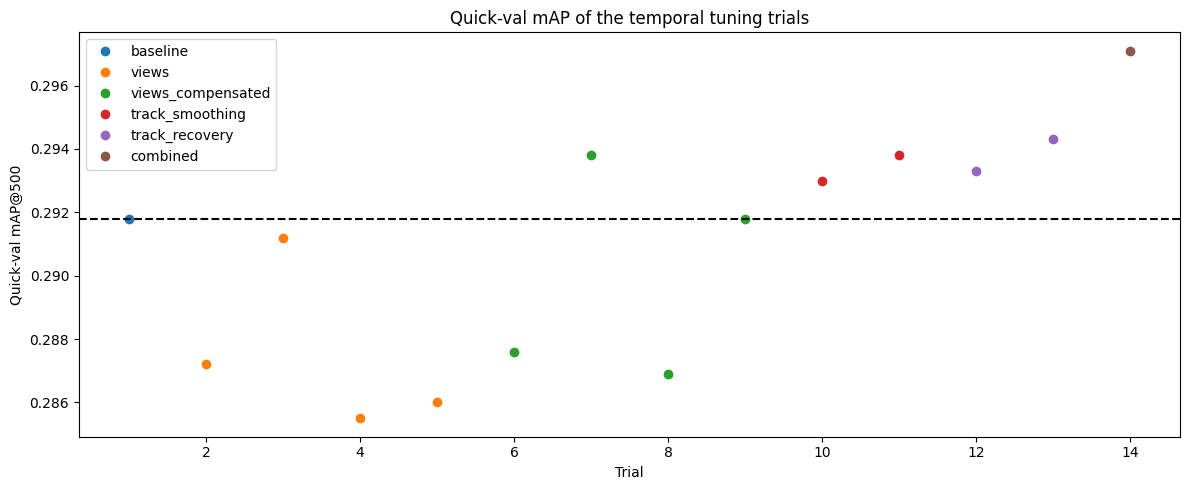

In [29]:
fig, ax = plt.subplots(figsize=FIGURE_SIZE)
for row_name in history["row"].unique(maintain_order=True).to_list():
    row_trials = history.filter(pl.col("row") == row_name)
    ax.plot(row_trials["step"], row_trials["val_mAP"], marker="o", linestyle="", label=row_name)
ax.axhline(baseline_quick_val_map, linestyle="--", color="black")
ax.set_title("Quick-val mAP of the temporal tuning trials")
ax.set_xlabel("Trial")
ax.set_ylabel("Quick-val mAP@500")
ax.legend()
save_figure(fig, "tuning_quick_val", history)

## Validation

The combined setting is applied to all val frames. Quick val is a subset of val and was used to tune the settings (and to select the checkpoints of the members behind P5b), so this score is slightly optimistic; `mAP_outside_quick_val` is the number on the frames that were not used for tuning. Speed protocol: the recorded `ms_per_image` of P5b plus the wall-clock time per val frame of the motion estimation and of this step (CPU, one process).

In [30]:
processing_started = time.perf_counter()
val_detections_by_key = apply_setting(
    combined_setting, val_clip_keys, val_base, val_matrices_by_clip, val_size_by_key, val_keys
)
temporal_ms_per_image = 1000 * (time.perf_counter() - processing_started + val_motion_seconds) / len(val_keys)
ms_per_image = source_result["ms_per_image"] + temporal_ms_per_image
val_predictions = to_coco_results(val_detections_by_key, val_image_id_by_key)
(OUTPUT_DIR / "val_predictions.json").write_text(json.dumps(val_predictions))
val_evaluator = evaluate_coco(val_ground_truth, val_predictions)
val_metrics = summarise_metrics(val_evaluator)
print(
    f"{len(val_predictions)} detections | mAP {val_metrics['mAP']:.4f} "
    f"| temporal {temporal_ms_per_image:.1f} ms/image | source {source_result['ms_per_image']:.1f} ms/image"
)

1423000 detections | mAP 0.2951 | temporal 150.3 ms/image | source 1848.1 ms/image


Per-clip AP and the mAP outside the quick-val frames of the combined detections. They are computed before `result.json` so that the file is complete. The per-clip table is described below.

In [31]:
per_clip_ap = build_per_clip_ap(val_predictions)
combined_row = {
    **build_metric_row(val_evaluator, per_clip_ap),
    "mAP_outside_quick_val": compute_outside_quick_val_map(val_predictions),
}
print(f"combined: mAP {combined_row['mAP']:.4f} | outside quick val {combined_row['mAP_outside_quick_val']:.4f}")

combined: mAP 0.2951 | outside quick val 0.2950


`result.json` writer: the core keys are checked before writing. Keys that do not apply to a post-processing run (`imgsz`, `epochs_planned`, `epochs_run`, `best_epoch`, `batch`, `lr`) are `null`; `train_hours` is the wall-clock time of the tuning search, and the hours behind the members of P5b are in the P5b result (`source_train_hours`).

In [32]:
REQUIRED_RESULT_KEYS = [
    "run",
    "notebook",
    "model",
    "family",
    "variant",
    "parent_run",
    "changed_params",
    "seed",
    "imgsz",
    "epochs_planned",
    "epochs_run",
    "best_epoch",
    "batch",
    "lr",
    "train_frames",
    "val_frames",
    "frame_step",
    "ignore_strategy",
    "mAP",
    "mAP_maxdet100",
    "AP50",
    "AP75",
    "AP_small",
    "AP_medium",
    "AP_large",
    "AR500",
    "ms_per_image",
    "speed_protocol",
    "train_hours",
    "gpu_name",
    "versions",
    "started_at",
    "finished_at",
]
FAMILIES = ["two_stage", "one_stage_anchor", "anchor_free", "query", "pipeline"]
VARIANTS = ["initial", "tuned"]


def write_result(result: dict[str, object]) -> None:
    missing_keys = [key for key in REQUIRED_RESULT_KEYS if key not in result]
    if missing_keys:
        raise ValueError(f"result.json is missing core keys: {missing_keys}")
    if result["family"] not in FAMILIES or result["variant"] not in VARIANTS:
        raise ValueError(f"Invalid family or variant: {result['family']}, {result['variant']}")
    (OUTPUT_DIR / "result.json").write_text(json.dumps(result, indent=2))

The run summary, shown as a one-row table (without the list and dict entries).

In [33]:
result: dict[str, object] = {
    "run": RUN_NAME,
    "notebook": f"new-notebooks/{RUN_NAME}.ipynb",
    "model": MODEL_NAME,
    "family": FAMILY,
    "variant": VARIANT,
    "parent_run": PARENT_RUN,
    "changed_params": CHANGED_PARAMS,
    "seed": SEED,
    "imgsz": None,
    "epochs_planned": None,
    "epochs_run": None,
    "best_epoch": None,
    "batch": None,
    "lr": None,
    "train_frames": train_frames.height,
    "val_frames": val_frames.height,
    "frame_step": FRAME_STEP,
    "ignore_strategy": IGNORE_STRATEGY,
    **val_metrics,
    "ms_per_image": round(ms_per_image, 1),
    "speed_protocol": SPEED_PROTOCOL,
    "train_hours": round(tuning_hours, 2),
    "gpu_name": gpu_name,
    "versions": package_versions,
    "started_at": started_at,
    "finished_at": datetime.now(UTC).isoformat(timespec="seconds"),
    "source_kernels": list(SOURCE_KERNELS),
    "source_mAP": source_result["mAP"],
    "source_ms_per_image": round(source_result["ms_per_image"], 1),
    "source_train_hours": round(source_result["train_hours"], 2),
    "temporal_ms_per_image": round(temporal_ms_per_image, 1),
    "mAP_outside_quick_val": combined_row["mAP_outside_quick_val"],
    "baseline_mAP_outside_quick_val": baseline_row["mAP_outside_quick_val"],
    "temporal_setting": asdict(combined_setting),
    "accepted_rows": accepted_rows,
    "quick_val_mAP_baseline": baseline_quick_val_map,
    "quick_val_mAP_tuned": combined_quick_val_map,
}
write_result(result)
pl.DataFrame([{key: value for key, value in result.items() if not isinstance(value, list | dict)}])

run,notebook,model,family,variant,parent_run,seed,imgsz,epochs_planned,epochs_run,best_epoch,batch,lr,train_frames,val_frames,frame_step,ignore_strategy,mAP,mAP_maxdet100,AP50,AP75,AP_small,AP_medium,AP_large,AR500,ms_per_image,speed_protocol,train_hours,gpu_name,started_at,finished_at,source_mAP,source_ms_per_image,source_train_hours,temporal_ms_per_image,mAP_outside_quick_val,baseline_mAP_outside_quick_val,quick_val_mAP_baseline,quick_val_mAP_tuned
str,str,str,str,str,str,i64,null,null,null,null,null,null,i64,i64,i64,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,f64,str,str,str,f64,f64,f64,f64,f64,f64,f64,f64
"""pipeline-temporal""","""new-notebooks/pipeline-tempora…","""temporal post-processing of th…","""pipeline""","""tuned""","""pipeline-ensemble-extended""",42,null,null,null,null,null,null,4868,2846,5,"""per_image_mean_fill""",0.2951,0.2942,0.5501,0.2788,0.1535,0.274,0.4851,0.5128,1998.4,"""recorded ms_per_image of the P…",0.49,"""none (CPU session)""","""2026-11-05T23:52:14+00:00""","""2026-11-06T01:12:37+00:00""",0.2904,1848.1,2.34,150.3,0.295,0.2901,0.2918,0.2971


Per-class AP and AP50 on all val frames. How to read this table: one row per class, AP is AP@[.50:.95] at 500 detections per frame, empty when the class has no GT in val.

In [34]:
per_class_ap = build_per_class_ap(val_evaluator)
per_class_ap.write_csv(OUTPUT_DIR / "per_class_ap.csv")
per_class_ap

class_id,class_name,AP,AP50
i64,str,f64,f64
0,"""person""",0.3203,0.7231
1,"""bicycle""",0.2952,0.6288
2,"""car""",0.4449,0.683
3,"""van""",0.3141,0.5275
4,"""truck""",0.3931,0.6269
5,"""tricycle""",0.3236,0.6429
6,"""bus""",0.1051,0.1395
7,"""motor""",0.1647,0.429


Per-clip AP of the combined detections (see the description above). How to read this table: one row per val clip; `AP` is AP@[.50:.95] at 500 detections per frame (the headline definition), `AP50` is AP at IoU 0.5, `AP_small` is AP on objects under 32² px, empty when the clip has no GT of that size. Written to `per_clip_ap.csv`.

In [35]:
per_clip_ap.write_csv(OUTPUT_DIR / "per_clip_ap.csv")
per_clip_ap

clip,frames,AP,AP50,AP_small
str,i64,f64,f64,f64
"""uav0000086_00000_v""",464,0.3265,0.7092,0.2734
"""uav0000117_02622_v""",349,0.337,0.6165,0.0421
"""uav0000137_00458_v""",233,0.3686,0.751,0.0085
"""uav0000182_00000_v""",363,0.2481,0.526,0.1828
"""uav0000268_05773_v""",978,0.1701,0.2777,0.0126
"""uav0000305_00000_v""",184,0.3956,0.5553,0.0424
"""uav0000339_00001_v""",275,0.3195,0.5513,0.094


AP and recall by object size on all val frames, taken from the full-val evaluator. Buckets are COCO's, in original pixels: small < 32², medium < 96², large otherwise. How to read this table: `objects` counts the non-crowd val GT boxes in the bucket (the `all` row is the total, so rows overlap). `AP` and `AP50` are precision-based at 500 detections per frame. `AR500` is the recall averaged over IoU .50:.95 and `recall50` is the recall at IoU 0.5, both at 500 detections per frame. Written to `size_breakdown.csv`.

In [36]:
def read_eval_array(evaluator: COCOeval, name: str) -> np.ndarray:
    values = evaluator.eval[name]
    if not isinstance(values, np.ndarray):
        raise RuntimeError(f"COCOeval has no {name} array; call accumulate() first")
    return values


def build_size_breakdown(evaluator: COCOeval) -> pl.DataFrame:
    precision = read_eval_array(evaluator, "precision")
    recall = read_eval_array(evaluator, "recall")
    areas = np.concatenate(
        [(targets[:, 2] - targets[:, 0]) * (targets[:, 3] - targets[:, 1]) for targets in val_targets_by_key.values()]
    )
    object_counts = [
        len(areas),
        int((areas < SMALL_AREA).sum()),
        int(((areas >= SMALL_AREA) & (areas < MEDIUM_AREA)).sum()),
        int((areas >= MEDIUM_AREA).sum()),
    ]
    return pl.DataFrame(
        [
            {
                "size": size_name,
                "objects": object_count,
                "AP": average_valid_precision(precision[:, :, :, area_index, -1]),
                "AP50": average_valid_precision(precision[0, :, :, area_index, -1]),
                "AR500": average_valid_precision(recall[:, :, area_index, -1]),
                "recall50": average_valid_precision(recall[0, :, area_index, -1]),
            }
            for area_index, (size_name, object_count) in enumerate(
                zip(["all", "small", "medium", "large"], object_counts, strict=True)
            )
        ],
        schema={
            "size": pl.String,
            "objects": pl.Int64,
            "AP": pl.Float64,
            "AP50": pl.Float64,
            "AR500": pl.Float64,
            "recall50": pl.Float64,
        },
    )


size_breakdown = build_size_breakdown(val_evaluator)
size_breakdown.write_csv(OUTPUT_DIR / "size_breakdown.csv")
size_breakdown

size,objects,AP,AP50,AR500,recall50
str,i64,f64,f64,f64,f64
"""all""",114132,0.2951,0.5501,0.5128,0.8369
"""small""",21910,0.1535,0.3983,0.3244,0.7245
"""medium""",79357,0.274,0.5398,0.4853,0.8265
"""large""",12865,0.4851,0.7579,0.6843,0.9617


## Temporal ablation

The question: what does each mechanism give alone, and what do they give together, on all 2,846 val frames and on the 2,275 frames outside the quick-val set? Rows: `baseline` (the P5b detections), the four mechanisms with the best setting of their own quick-val trials, and `combined` (the setting applied above). A row whose best quick-val mAP did not beat the baseline is still evaluated here with its best setting; `is_accepted` says whether it entered `combined`. All rows use the same COCOeval, run one after another.

How to read this table: one row per configuration; the setting columns show the values used (an unused mechanism has weight 0). `quick_val_mAP` is the tuning score on the quick-val frames. `mAP` is AP@[.50:.95] at 500 detections per frame on all val frames, `mAP_outside_quick_val` the same on the frames outside quick val, `AP_small` is AP on objects under 32² px, `AP_bus` is the AP of the bus class, and `AP_<clip>` is the AP on that clip alone. `delta_mAP`, `delta_mAP_outside_quick_val` and `delta_AP_small` are the differences to the baseline row. Written to `temporal_ablation.csv`.

In [37]:
def evaluate_ablation_row(name: str, setting: TemporalSetting) -> dict[str, float]:
    started = time.time()
    detections_by_key = apply_setting(setting, val_clip_keys, val_base, val_matrices_by_clip, val_size_by_key, val_keys)
    row = evaluate_detections(detections_by_key)
    print(
        f"{name} | mAP {row['mAP']:.4f} | outside quick val {row['mAP_outside_quick_val']:.4f} "
        f"| {(time.time() - started) / 60:.1f} min",
        flush=True,
    )
    return row


quick_val_map_by_config = {
    REFERENCE_LABEL: baseline_quick_val_map,
    **quick_val_map_by_row,
    "combined": combined_quick_val_map,
}
ablation_specs = [
    (REFERENCE_LABEL, TemporalSetting(), baseline_row),
    *[(name, setting, None) for name, setting in best_setting_by_row.items()],
    ("combined", combined_setting, combined_row),
]
ablation_rows = [
    {
        "config": name,
        **asdict(setting),
        "is_accepted": name in accepted_rows,
        "quick_val_mAP": quick_val_map_by_config[name],
        **(row if row is not None else evaluate_ablation_row(name, setting)),
    }
    for name, setting, row in ablation_specs
]
ablation = pl.DataFrame(ablation_rows).with_columns(
    delta_mAP=(pl.col("mAP") - pl.col("mAP").first()).round(4),
    delta_mAP_outside_quick_val=(pl.col("mAP_outside_quick_val") - pl.col("mAP_outside_quick_val").first()).round(4),
    delta_AP_small=(pl.col("AP_small") - pl.col("AP_small").first()).round(4),
)
ablation.write_csv(OUTPUT_DIR / "temporal_ablation.csv")
ablation.select("config", "quick_val_mAP", "mAP", "mAP_outside_quick_val", "AP_small", "delta_mAP", "delta_AP_small")

views | mAP 0.2899 | outside quick val 0.2896 | 23.1 min
views_compensated | mAP 0.2915 | outside quick val 0.2910 | 23.0 min
track_smoothing | mAP 0.2925 | outside quick val 0.2923 | 19.5 min
track_recovery | mAP 0.2928 | outside quick val 0.2924 | 19.8 min


config,quick_val_mAP,mAP,mAP_outside_quick_val,AP_small,delta_mAP,delta_AP_small
str,f64,f64,f64,f64,f64,f64
"""baseline""",0.2918,0.2904,0.2901,0.1521,0.0,0.0
"""views""",0.2912,0.2899,0.2896,0.1509,-0.0005,-0.0012
"""views_compensated""",0.2938,0.2915,0.291,0.1529,0.0011,0.0008
"""track_smoothing""",0.2938,0.2925,0.2923,0.1531,0.0021,0.001
"""track_recovery""",0.2943,0.2928,0.2924,0.1539,0.0024,0.0018
"""combined""",0.2971,0.2951,0.295,0.1535,0.0047,0.0014


Ablation figure: full-val mAP@500 and AP_small for every configuration of the table above.

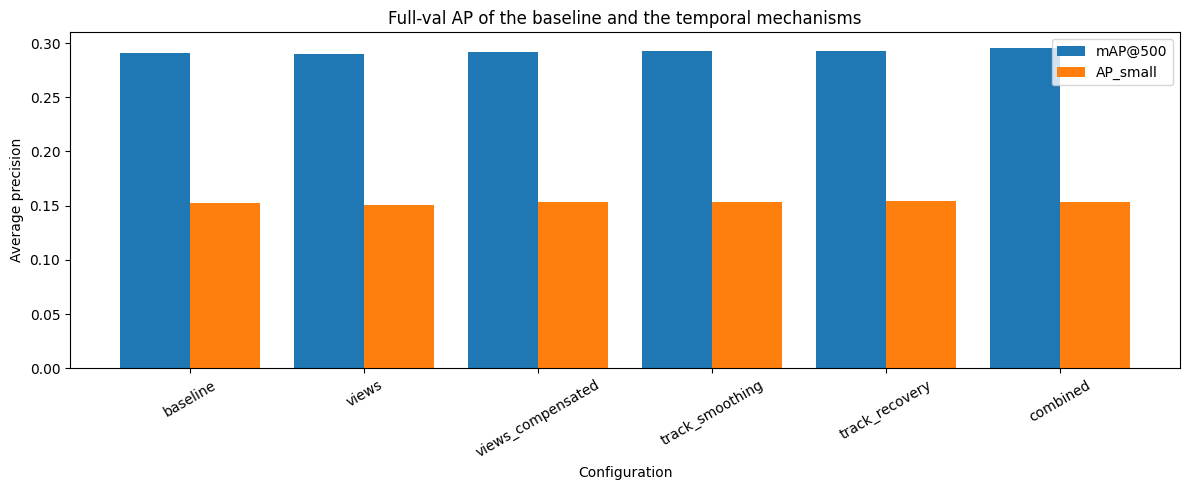

In [38]:
fig, ax = plt.subplots(figsize=FIGURE_SIZE)
positions = np.arange(ablation.height)
ax.bar(positions - 0.2, ablation["mAP"], width=0.4, label="mAP@500")
ax.bar(positions + 0.2, ablation["AP_small"], width=0.4, label="AP_small")
ax.set_xticks(positions, labels=ablation["config"].to_list())
ax.tick_params(axis="x", labelrotation=30)
ax.set_title("Full-val AP of the baseline and the temporal mechanisms")
ax.set_xlabel("Configuration")
ax.set_ylabel("Average precision")
ax.legend()
save_figure(fig, "temporal_ablation", ablation.select("config", "mAP", "mAP_outside_quick_val", "AP_small"))

## Noise and clip-metric diagnostics

The question: how large are the differences between the rows compared with the spread across the 7 val clips? The table has one row per ablation row, built from the per-clip AP columns of `temporal_ablation.csv`; no new detections are evaluated.

How to read this table: `AP_<clip>` is the AP on that clip. `clip_mean` is the unweighted mean of the 7 clip APs; `clip_mean_without_4k` is the same mean over the 6 clips without the 4K clip `uav0000268_05773_v` (34 % of val frames). For every row except the reference `baseline`, `delta_clip_mean` is the mean over clips of (AP of the row − AP of the baseline). `loo_delta_min` and `loo_delta_max` are the smallest and largest value of this mean when one clip is left out at a time (leave-one-clip-out). `bootstrap_delta_low` and `bootstrap_delta_high` are the 2.5 % and 97.5 % percentiles of the mean delta when the 7 clips are resampled with replacement `BOOTSTRAP_RESAMPLES` times (seeded generator, the same resamples for every row; Efron 1979). `positive_clips` is the number of clips on which the row is above the baseline. With 7 clips the intervals are coarse. The delta columns are empty in the baseline row. Written to `val_noise.csv`.

In [39]:
def summarise_clip_noise(
    clip_aps: np.ndarray, reference_aps: np.ndarray, is_four_k: np.ndarray, bootstrap_indices: np.ndarray
) -> dict[str, float]:
    deltas = clip_aps - reference_aps
    leave_one_out_means = [float(np.delete(deltas, index).mean()) for index in range(len(deltas))]
    bootstrap_means = deltas[bootstrap_indices].mean(axis=1)
    low, high = np.percentile(bootstrap_means, BOOTSTRAP_INTERVAL)
    return {
        "delta_clip_mean": round(float(deltas.mean()), 4),
        "loo_delta_min": round(min(leave_one_out_means), 4),
        "loo_delta_max": round(max(leave_one_out_means), 4),
        "bootstrap_delta_low": round(float(low), 4),
        "bootstrap_delta_high": round(float(high), 4),
        "positive_clips": int((deltas > 0).sum()),
    }


NOISE_DELTA_FIELDS = [
    "delta_clip_mean",
    "loo_delta_min",
    "loo_delta_max",
    "bootstrap_delta_low",
    "bootstrap_delta_high",
    "positive_clips",
]
clip_columns = [f"AP_{clip}" for clip in val_clips]
noise_runs = ablation
is_four_k = np.array([clip == FOUR_K_CLIP for clip in val_clips])
reference_aps = noise_runs.filter(pl.col("config") == REFERENCE_LABEL).select(clip_columns).to_numpy()[0]
bootstrap_indices = np.random.default_rng(SEED).integers(0, len(val_clips), size=(BOOTSTRAP_RESAMPLES, len(val_clips)))
noise_rows = []
for config, *clip_values in noise_runs.select("config", *clip_columns).iter_rows():
    clip_aps = np.array(clip_values)
    delta_fields = (
        summarise_clip_noise(clip_aps, reference_aps, is_four_k, bootstrap_indices)
        if config != REFERENCE_LABEL
        else dict.fromkeys(NOISE_DELTA_FIELDS, None)
    )
    noise_rows.append(
        {
            "run": config,
            **dict(zip(clip_columns, clip_values, strict=True)),
            "clip_mean": round(float(clip_aps.mean()), 4),
            "clip_mean_without_4k": round(float(clip_aps[~is_four_k].mean()), 4),
            **delta_fields,
        }
    )
val_noise = pl.DataFrame(noise_rows, infer_schema_length=None)
val_noise.write_csv(OUTPUT_DIR / "val_noise.csv")
val_noise

run,AP_uav0000086_00000_v,AP_uav0000117_02622_v,AP_uav0000137_00458_v,AP_uav0000182_00000_v,AP_uav0000268_05773_v,AP_uav0000305_00000_v,AP_uav0000339_00001_v,clip_mean,clip_mean_without_4k,delta_clip_mean,loo_delta_min,loo_delta_max,bootstrap_delta_low,bootstrap_delta_high,positive_clips
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64
"""baseline""",0.3053,0.3266,0.3678,0.2414,0.168,0.3846,0.3197,0.3019,0.3242,null,null,null,null,null,null
"""views""",0.3117,0.3288,0.3673,0.2321,0.1709,0.3904,0.312,0.3019,0.3237,-0.0,-0.0011,0.0015,-0.0047,0.0042,4
"""views_compensated""",0.3099,0.3302,0.3673,0.2403,0.1708,0.3883,0.3129,0.3028,0.3248,0.0009,0.0003,0.0022,-0.002,0.0034,4
"""track_smoothing""",0.3064,0.3292,0.369,0.2443,0.1692,0.3851,0.3199,0.3033,0.3256,0.0014,0.0011,0.0016,0.0007,0.0021,7
"""track_recovery""",0.3184,0.3335,0.3681,0.2462,0.1667,0.3908,0.3266,0.3072,0.3306,0.0053,0.004,0.0064,0.0021,0.0086,6
"""combined""",0.3265,0.337,0.3686,0.2481,0.1701,0.3956,0.3195,0.3093,0.3325,0.0074,0.0051,0.0087,0.0029,0.0135,6


## Submission

Apply the combined setting to the test frames of the P5b `submission.csv` and write `submission.csv`: one row per `test_images.csv` row in that order, 0-based class ids, top-left `x y w h` in original pixels, top 500 by score, empty string for frames without detections. Test frames are consecutive within each clip, so the neighbours are the true adjacent frames.

In [40]:
def format_prediction_string(boxes: np.ndarray, scores: np.ndarray, class_ids: np.ndarray) -> str:
    top_indices = np.argsort(-scores, kind="stable")[:MAX_DETECTIONS]
    groups = []
    for (x1, y1, x2, y2), score, class_id in zip(
        boxes[top_indices].tolist(), scores[top_indices].tolist(), class_ids[top_indices].tolist(), strict=True
    ):
        width = round(x2 - x1, 2)
        height = round(y2 - y1, 2)
        if width > 0 and height > 0:
            groups.append(f"{int(class_id)} {score:.4f} {x1:.2f} {y1:.2f} {width:.2f} {height:.2f}")
    return " ".join(groups)


test_detections_by_key = apply_setting(
    combined_setting, test_clip_keys, test_base, test_matrices_by_clip, test_size_by_key, test_keys
)
prediction_by_image_id = {
    image_id: format_prediction_string(*test_detections_by_key[key])
    for image_id, key in test_images.select("image_id", "frame_key").iter_rows()
}
submission = test_images.select("image_id").with_columns(
    PredictionString=pl.col("image_id").replace_strict(prediction_by_image_id, default="", return_dtype=pl.String)
)
submission.write_csv(OUTPUT_DIR / "submission.csv")
print(f"submission.csv: {submission.height} rows, {(submission['PredictionString'] == '').sum()} empty")

submission.csv: 3811 rows, 0 empty


Format checks on the file as written to disk, against `test_images.csv` and the fixed columns `image_id,PredictionString` (the competition data has no `sample_submission.csv`). The results go to `submission_check.json`, and the notebook raises if any check fails.

In [41]:
SUBMISSION_COLUMNS = ["image_id", "PredictionString"]
SUBMISSION_FIELDS = ["class_id", "score", "x", "y", "w", "h"]


def check_submission(submission: pl.DataFrame, test_images: pl.DataFrame) -> dict[str, bool]:
    groups = (
        submission.join(test_images.select("image_id", "width", "height"), on="image_id", how="left")
        .filter(pl.col("PredictionString") != "")
        .with_columns(values=pl.col("PredictionString").str.split(" ").cast(pl.List(pl.Float64)))
    )
    boxes = groups.select(
        "width",
        "height",
        *[pl.col("values").list.gather_every(6, offset).alias(name) for offset, name in enumerate(SUBMISSION_FIELDS)],
    ).explode(SUBMISSION_FIELDS)
    return {
        "columns_match_submission_format": submission.columns == SUBMISSION_COLUMNS,
        "image_ids_match_test_images_order": submission["image_id"].equals(test_images["image_id"]),
        "image_ids_unique": bool(submission["image_id"].is_unique().all()),
        "values_multiple_of_six": bool(groups.select((pl.col("values").list.len() % 6 == 0).all()).item()),
        "at_most_max_detections_per_image": bool(
            groups.select((pl.col("values").list.len() <= 6 * MAX_DETECTIONS).all()).item()
        ),
        "class_ids_are_valid_integers": bool(
            boxes.select(
                (
                    pl.col("class_id").is_between(0, len(CLASSES) - 1)
                    & (pl.col("class_id") == pl.col("class_id").floor())
                ).all()
            ).item()
        ),
        "scores_in_unit_interval": bool(boxes["score"].is_between(0, 1).all()),
        "sizes_positive": bool(boxes.select(((pl.col("w") > 0) & (pl.col("h") > 0)).all()).item()),
        "boxes_inside_image": bool(
            boxes.select(
                (
                    (pl.col("x") >= -1)
                    & (pl.col("y") >= -1)
                    & (pl.col("x") + pl.col("w") <= pl.col("width") + 1)
                    & (pl.col("y") + pl.col("h") <= pl.col("height") + 1)
                ).all()
            ).item()
        ),
    }


submission_on_disk = pl.read_csv(
    OUTPUT_DIR / "submission.csv", schema={"image_id": pl.String, "PredictionString": pl.String}
).with_columns(pl.col("PredictionString").fill_null(""))
submission_check = check_submission(submission_on_disk, test_images)
(OUTPUT_DIR / "submission_check.json").write_text(json.dumps(submission_check, indent=2))
failed_checks = [name for name, is_passed in submission_check.items() if not is_passed]
if failed_checks:
    raise ValueError(f"Submission checks failed: {failed_checks}")
submission_check

{'columns_match_submission_format': True,
 'image_ids_match_test_images_order': True,
 'image_ids_unique': True,
 'values_multiple_of_six': True,
 'at_most_max_detections_per_image': True,
 'class_ids_are_valid_integers': True,
 'scores_in_unit_interval': True,
 'sizes_positive': True,
 'boxes_inside_image': True}

## References

- Solovyev, Wang, Gabruseva. Weighted boxes fusion: ensembling boxes from different object detection models. arXiv:1910.13302 (WBF, class-wise fusion, confidence rescaling; the neighbour views are fused with it).
- `ensemble-boxes` 1.0.10 (`weighted_boxes_fusion`), MIT licence: https://github.com/ZFTurbo/Weighted-Boxes-Fusion
- Han et al. Seq-NMS for video object detection. arXiv:1602.08465 (linking boxes of adjacent frames and rescoring along the sequence; idea of the neighbour views).
- Kang et al. T-CNN: tubelets with convolutional neural networks for object detection from videos. arXiv:1604.02532 (propagation of detections to neighbouring frames and rescoring along tracks).
- Bewley, Ge, Ott, Ramos, Upcroft. Simple online and realtime tracking. arXiv:1602.00763 (IoU association of detections with tracks; SORT uses the Hungarian algorithm, this notebook a greedy IoU matching).
- Zhang et al. ByteTrack: multi-object tracking by associating every detection box. arXiv:2110.06864 (two-stage association of high-score and low-score detections; repository https://github.com/ifzhang/ByteTrack, MIT licence; no code is copied).
- Rublee, Rabaud, Konolige, Bradski. ORB: an efficient alternative to SIFT or SURF. ICCV 2011, https://doi.org/10.1109/ICCV.2011.6126544 (keypoints and descriptors for the motion estimation).
- Fischler, Bolles. Random sample consensus. Communications of the ACM 24(6), 1981, https://doi.org/10.1145/358669.358692 (robust homography fit).
- OpenCV (`cv2.ORB_create`, `cv2.BFMatcher`, `cv2.findHomography`), Apache-2.0: https://github.com/opencv/opencv and https://docs.opencv.org/4.x/d9/d0c/group__calib3d.html
- Lin et al. Microsoft COCO: Common Objects in Context (metric definitions). arXiv:1405.0312.
- Zhu et al. Detection and Tracking Meet Drones Challenge (VisDrone, ignored regions). arXiv:2001.06303.
- Efron. Bootstrap methods: another look at the jackknife. Annals of Statistics 7(1), 1979, https://doi.org/10.1214/aos/1176344552 (bootstrap and leave-one-out resampling of clips in `val_noise.csv`).
- pycocotools (COCOeval), BSD-2-Clause: https://github.com/cocodataset/cocoapi
- torchvision `ops.box_iou`, BSD-3-Clause: https://github.com/pytorch/vision/blob/main/torchvision/ops/boxes.py
- Source run (kernel source): P5b `pipeline-ensemble-extended` (its report is in `experiments/` and `EXPERIMENTS.md` once it has run). Its members include the legacy runs `faster-cnn-5`, `rt-detr-tuned-lr` (Ultralytics RT-DETR, AGPL-3.0: https://github.com/ultralytics/ultralytics), `yolo-3-1280` and `retinanet`.
- Protocol code (split, COCO evaluation, per-clip AP, size breakdown, `result.json`, source loading, submission and checks): copied from `new-notebooks/pipeline-ensemble-wbf.ipynb` (itself copied from `new-notebooks/pipeline-class-balance.ipynb`); no legacy notebook code is used.
- EDA notebook `notebooks/eda.ipynb` and its summary `EDA.md` (§1 frame counts, §3 sizes, §5 consecutive test frames and the 4K val clip, §8 track IoU by frame gap).